## AEMO Data Quality Assessment and Preprocessing Summary

The AEMO SA1 and NSW1 datasets covering 2018–2023 were inspected directly from the project repository before modelling to identify potential time-series data quality issues and establish a consistent preprocessing procedure.

The repository contains **72 monthly CSV files for each region**, covering January 2018 to December 2023.

#### Raw Data Quality Assessment

- **Missing values:** No missing values were identified in `REGION`, `SETTLEMENTDATE`, `TOTALDEMAND`, `RRP`, or `PERIODTYPE` for either SA1 or NSW1.

- **Duplicate timestamps:** No duplicated `SETTLEMENTDATE` values were identified in either region.

- **Unexpected time gaps:** No unexpected temporal gaps were identified when the expected sampling frequency for each period was considered.

- **Sampling frequency:** The raw datasets contain two sampling frequencies. Both regions use 30-minute observations before October 2021 and 5-minute observations after the frequency transition.

- **Frequency transition:** The first 5-minute observation occurs at `2021-10-01 00:05:00` in both SA1 and NSW1.

The inspection around the transition confirmed that the sequence changes from:

`23:00 → 23:30 → 00:00`

to:

`00:05 → 00:10 → 00:15 → 00:20 → 00:25 → 00:30`

in both regions.

#### Standardisation to 30-Minute Resolution

A consistent temporal resolution is required before forecasting and drift detection so that a change in sampling frequency is not incorrectly interpreted as a change in electricity-demand behaviour.

The complete dataset was therefore standardised to **30-minute resolution**.

Observations before the frequency transition were retained at their original 30-minute resolution. From `2021-10-01 00:05:00` onward, each group of six consecutive 5-minute `TOTALDEMAND` observations was averaged to produce one 30-minute demand observation.

Because the timestamps represent the end of the corresponding interval:

`00:05, 00:10, 00:15, 00:20, 00:25, 00:30`

are aggregated into the 30-minute interval ending at:

`00:30`.

#### Validation After Standardisation

The resulting datasets were validated before being used for modelling:

- SA1 contains **105,168** standardized observations.
- NSW1 contains **105,168** standardized observations.
- Every consecutive observation is separated by exactly **30 minutes**.
- No duplicate timestamps remain.
- No missing `TOTALDEMAND` values are present.
- SA1 and NSW1 have exactly matching standardized timestamps.
- No raw observations required missing-value imputation or duplicate removal because these problems were not present in the original datasets.

#### Chronological Data Split

After standardisation, the same fixed chronological split was applied to both regions:

- **Training:** 35,039 observations
- **Calibration:** 2,880 observations
- **Test stream:** 67,249 observations

The split is strictly chronological and non-overlapping, and all **105,168 observations** are accounted for.

The reusable loading, 30-minute standardisation, and chronological splitting procedures are maintained centrally in `src/data_loader.py`. This notebook documents the data inspection and validation used to justify those preprocessing decisions and provides the visual evidence required before forecasting and concept-drift analysis.

In [1]:
%pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 17.1 MB/s  0:00:00m0:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 19.9 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 22.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 24.5 MB/s  0:00:00m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 22.5 MB/s  0:00:00m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [matplotlib]8 [matplotlib]

[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
%pip install pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 17.2 MB/s  0:00:00m0:00:010:01

[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [4]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# Notebook is located in:
# notebook/

# Therefore the project root is one level above
project_root = Path.cwd().parent

# Raw data folders
data_path = project_root / "data"

sa1_path = data_path / "SA1"
nsw1_path = data_path / "NSW1"


print("Project root:", project_root)
print("Data folder:", data_path)
print("SA1 folder:", sa1_path)
print("NSW1 folder:", nsw1_path)

Project root: /workspaces/Detecting-and-Adapting-to-Concept-Drift-in-Time-Series-Forecasting
Data folder: /workspaces/Detecting-and-Adapting-to-Concept-Drift-in-Time-Series-Forecasting/data
SA1 folder: /workspaces/Detecting-and-Adapting-to-Concept-Drift-in-Time-Series-Forecasting/data/SA1
NSW1 folder: /workspaces/Detecting-and-Adapting-to-Concept-Drift-in-Time-Series-Forecasting/data/NSW1


In [5]:

# Verify that the project data folders are accessible
print("SA1 folder exists:", sa1_path.exists())
print("NSW1 folder exists:", nsw1_path.exists())

sa1_files = sorted(sa1_path.glob("*.csv"))
nsw1_files = sorted(nsw1_path.glob("*.csv"))

print()
print("SA1 CSV files:", len(sa1_files))
print("NSW1 CSV files:", len(nsw1_files))

print()
print("First SA1 file:", sa1_files[0].name)
print("Last SA1 file:", sa1_files[-1].name)

print()
print("First NSW1 file:", nsw1_files[0].name)
print("Last NSW1 file:", nsw1_files[-1].name)

SA1 folder exists: True
NSW1 folder exists: True

SA1 CSV files: 72
NSW1 CSV files: 72

First SA1 file: PRICE_AND_DEMAND_201801_SA1.csv
Last SA1 file: PRICE_AND_DEMAND_202312_SA1.csv

First NSW1 file: PRICE_AND_DEMAND_201801_NSW1.csv
Last NSW1 file: PRICE_AND_DEMAND_202312_NSW1.csv


In [6]:
# Load all SA1 monthly files
sa1_frames = [
    pd.read_csv(file)
    for file in sa1_files
]

sa1_data = pd.concat(
    sa1_frames,
    ignore_index=True
)

# Load all NSW1 monthly files
nsw1_frames = [
    pd.read_csv(file)
    for file in nsw1_files
]

nsw1_data = pd.concat(
    nsw1_frames,
    ignore_index=True
)

print("SA1 shape:", sa1_data.shape)
print("NSW1 shape:", nsw1_data.shape)

SA1 shape: (302448, 5)
NSW1 shape: (302448, 5)


In [7]:
# Convert SETTLEMENTDATE to datetime

sa1_data["SETTLEMENTDATE"] = pd.to_datetime(
    sa1_data["SETTLEMENTDATE"]
)

nsw1_data["SETTLEMENTDATE"] = pd.to_datetime(
    nsw1_data["SETTLEMENTDATE"]
)

# Sort chronologically

sa1_data = (
    sa1_data
    .sort_values("SETTLEMENTDATE")
    .reset_index(drop=True)
)

nsw1_data = (
    nsw1_data
    .sort_values("SETTLEMENTDATE")
    .reset_index(drop=True)
)

print("SA1 date range:")
print(
    sa1_data["SETTLEMENTDATE"].min(),
    "to",
    sa1_data["SETTLEMENTDATE"].max()
)

print()

print("NSW1 date range:")
print(
    nsw1_data["SETTLEMENTDATE"].min(),
    "to",
    nsw1_data["SETTLEMENTDATE"].max()
)

SA1 date range:
2018-01-01 00:30:00 to 2024-01-01 00:00:00

NSW1 date range:
2018-01-01 00:30:00 to 2024-01-01 00:00:00


In [8]:
print("SA1 duplicate timestamps:",
      sa1_data["SETTLEMENTDATE"].duplicated().sum())

print("NSW1 duplicate timestamps:",
      nsw1_data["SETTLEMENTDATE"].duplicated().sum())

print()

print("SA1 missing values:")
print(sa1_data.isna().sum())

print()

print("NSW1 missing values:")
print(nsw1_data.isna().sum())

SA1 duplicate timestamps: 0
NSW1 duplicate timestamps: 0

SA1 missing values:
REGION            0
SETTLEMENTDATE    0
TOTALDEMAND       0
RRP               0
PERIODTYPE        0
dtype: int64

NSW1 missing values:
REGION            0
SETTLEMENTDATE    0
TOTALDEMAND       0
RRP               0
PERIODTYPE        0
dtype: int64


In [9]:
# Calculate time differences between consecutive observations

sa1_time_diff = sa1_data["SETTLEMENTDATE"].diff()
nsw1_time_diff = nsw1_data["SETTLEMENTDATE"].diff()

print("SA1 time intervals:")
print(sa1_time_diff.value_counts().sort_index())

print("\nNSW1 time intervals:")
print(nsw1_time_diff.value_counts().sort_index())

SA1 time intervals:
SETTLEMENTDATE
0 days 00:05:00    236736
0 days 00:30:00     65711
Name: count, dtype: int64

NSW1 time intervals:
SETTLEMENTDATE
0 days 00:05:00    236736
0 days 00:30:00     65711
Name: count, dtype: int64


In [10]:
# Find the first 5-minute observation in each region

sa1_diff = sa1_data["SETTLEMENTDATE"].diff()
nsw1_diff = nsw1_data["SETTLEMENTDATE"].diff()

sa1_first_5min_idx = sa1_diff[
    sa1_diff == pd.Timedelta(minutes=5)
].index[0]

nsw1_first_5min_idx = nsw1_diff[
    nsw1_diff == pd.Timedelta(minutes=5)
].index[0]


print(
    "SA1 first 5-minute observation:",
    sa1_data.loc[
        sa1_first_5min_idx,
        "SETTLEMENTDATE"
    ]
)

print(
    "NSW1 first 5-minute observation:",
    nsw1_data.loc[
        nsw1_first_5min_idx,
        "SETTLEMENTDATE"
    ]
)

SA1 first 5-minute observation: 2021-10-01 00:05:00
NSW1 first 5-minute observation: 2021-10-01 00:05:00


In [11]:
# Inspect observations around the frequency transition

transition_start = pd.Timestamp("2021-09-30 23:00:00")
transition_end = pd.Timestamp("2021-10-01 00:30:00")

print("SA1 around the transition:")
display(
    sa1_data.loc[
        (sa1_data["SETTLEMENTDATE"] >= transition_start)
        &
        (sa1_data["SETTLEMENTDATE"] <= transition_end),
        ["SETTLEMENTDATE", "TOTALDEMAND"]
    ]
)

print("NSW1 around the transition:")
display(
    nsw1_data.loc[
        (nsw1_data["SETTLEMENTDATE"] >= transition_start)
        &
        (nsw1_data["SETTLEMENTDATE"] <= transition_end),
        ["SETTLEMENTDATE", "TOTALDEMAND"]
    ]
)

SA1 around the transition:


,SETTLEMENTDATE,TOTALDEMAND
65709,2021-09-30 23:00:00,1262.69
65710,2021-09-30 23:30:00,1230.80
65711,2021-10-01 00:00:00,1360.13
65712,2021-10-01 00:05:00,1376.74
65713,2021-10-01 00:10:00,1338.87
65714,2021-10-01 00:15:00,1323.73
65715,2021-10-01 00:20:00,1336.61
65716,2021-10-01 00:25:00,1326.17
65717,2021-10-01 00:30:00,1314.58


NSW1 around the transition:


,SETTLEMENTDATE,TOTALDEMAND
65709,2021-09-30 23:00:00,7416.77
65710,2021-09-30 23:30:00,7338.21
65711,2021-10-01 00:00:00,7318.60
65712,2021-10-01 00:05:00,7263.77
65713,2021-10-01 00:10:00,7263.44
65714,2021-10-01 00:15:00,7301.17
65715,2021-10-01 00:20:00,7255.16
65716,2021-10-01 00:25:00,7185.16
65717,2021-10-01 00:30:00,7163.84


In [12]:
# Check for unexpected gaps in the raw data

transition = pd.Timestamp("2021-10-01 00:05:00")


def check_raw_gaps(data, region_name):

    # Time difference between consecutive observations
    time_diff = data["SETTLEMENTDATE"].diff()

    # Before the frequency transition:
    # expected difference = 30 minutes
    before_mask = (
        data["SETTLEMENTDATE"] < transition
    )

    unexpected_before = data.loc[
        before_mask
        & time_diff.notna()
        & (time_diff != pd.Timedelta(minutes=30)),
        ["SETTLEMENTDATE"]
    ].copy()

    # From the first 5-minute observation onward:
    # expected difference = 5 minutes
    after_mask = (
        data["SETTLEMENTDATE"] >= transition
    )

    unexpected_after = data.loc[
        after_mask
        & (time_diff != pd.Timedelta(minutes=5)),
        ["SETTLEMENTDATE"]
    ].copy()

    print(region_name)
    print(
        "Unexpected gaps before transition:",
        len(unexpected_before)
    )
    print(
        "Unexpected gaps after transition:",
        len(unexpected_after)
    )


check_raw_gaps(sa1_data, "SA1")
check_raw_gaps(nsw1_data, "NSW1")

SA1
Unexpected gaps before transition: 0
Unexpected gaps after transition: 0
NSW1
Unexpected gaps before transition: 0
Unexpected gaps after transition: 0


## Standardising the AEMO Data to 30-Minute Intervals

The AEMO demand data changes from 30-minute observations to
5-minute observations from 1 October 2021.

For consistency across the full forecasting period, the 5-minute
portion of the dataset is converted to 30-minute resolution.

The original 30-minute observations are retained unchanged.
For the 5-minute period, six consecutive 5-minute `TOTALDEMAND`
observations are averaged to produce one 30-minute demand value.

Particular care is taken with timestamp alignment. The AEMO
timestamps represent the end of the corresponding interval.
Therefore, observations at:

`00:05, 00:10, 00:15, 00:20, 00:25, 00:30`

are aggregated into the 30-minute interval ending at:

`00:30`.

Only complete 30-minute intervals containing all six expected
5-minute observations are retained. The resulting series is then
validated before it is used for the fixed Train / Calibration /
Test split.

In [13]:
import sys

# Make the project root importable
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.data_loader import standardize_to_30min


# Apply the shared standardisation function
sa1_30min = standardize_to_30min(sa1_data)
nsw1_30min = standardize_to_30min(nsw1_data)

print("SA1 standardized shape:", sa1_30min.shape)
print("NSW1 standardized shape:", nsw1_30min.shape)

SA1 standardized shape: (105168, 2)
NSW1 standardized shape: (105168, 2)


In [14]:
transition_start = pd.Timestamp("2021-09-30 23:00:00")
transition_end = pd.Timestamp("2021-10-01 01:00:00")

print("SA1 after standardisation:")
display(
    sa1_30min.loc[
        (sa1_30min["SETTLEMENTDATE"] >= transition_start)
        &
        (sa1_30min["SETTLEMENTDATE"] <= transition_end),
        ["SETTLEMENTDATE", "TOTALDEMAND"]
    ]
)

print("NSW1 after standardisation:")
display(
    nsw1_30min.loc[
        (nsw1_30min["SETTLEMENTDATE"] >= transition_start)
        &
        (nsw1_30min["SETTLEMENTDATE"] <= transition_end),
        ["SETTLEMENTDATE", "TOTALDEMAND"]
    ]
)

SA1 after standardisation:


,SETTLEMENTDATE,TOTALDEMAND
65709,2021-09-30 23:00:00,1262.690000
65710,2021-09-30 23:30:00,1230.800000
65711,2021-10-01 00:00:00,1360.130000
65712,2021-10-01 00:30:00,1336.116667
65713,2021-10-01 01:00:00,1319.851667


NSW1 after standardisation:


,SETTLEMENTDATE,TOTALDEMAND
65709,2021-09-30 23:00:00,7416.770000
65710,2021-09-30 23:30:00,7338.210000
65711,2021-10-01 00:00:00,7318.600000
65712,2021-10-01 00:30:00,7238.756667
65713,2021-10-01 01:00:00,7097.568333


In [15]:
# Validate the standardized 30-minute datasets

print("SA1 intervals:")
print(
    sa1_30min["SETTLEMENTDATE"]
    .diff()
    .value_counts()
)

print("\nNSW1 intervals:")
print(
    nsw1_30min["SETTLEMENTDATE"]
    .diff()
    .value_counts()
)

print("\nSA1 duplicate timestamps:",
      sa1_30min["SETTLEMENTDATE"].duplicated().sum())

print("NSW1 duplicate timestamps:",
      nsw1_30min["SETTLEMENTDATE"].duplicated().sum())

print("\nSA1 missing TOTALDEMAND:",
      sa1_30min["TOTALDEMAND"].isna().sum())

print("NSW1 missing TOTALDEMAND:",
      nsw1_30min["TOTALDEMAND"].isna().sum())

SA1 intervals:
SETTLEMENTDATE
0 days 00:30:00    105167
Name: count, dtype: int64

NSW1 intervals:
SETTLEMENTDATE
0 days 00:30:00    105167
Name: count, dtype: int64

SA1 duplicate timestamps: 0
NSW1 duplicate timestamps: 0

SA1 missing TOTALDEMAND: 0
NSW1 missing TOTALDEMAND: 0


In [16]:
from src.data_loader import split_aemo_data

# Apply the project's fixed chronological split
train_sa1, calibration_sa1, test_sa1 = split_aemo_data(
    sa1_30min
)

train_nsw1, calibration_nsw1, test_nsw1 = split_aemo_data(
    nsw1_30min
)

print("SA1")
print("Train:", len(train_sa1))
print("Calibration:", len(calibration_sa1))
print("Test:", len(test_sa1))

print("\nNSW1")
print("Train:", len(train_nsw1))
print("Calibration:", len(calibration_nsw1))
print("Test:", len(test_nsw1))

SA1
Train: 35039
Calibration: 2880
Test: 67249

NSW1
Train: 35039
Calibration: 2880
Test: 67249


In [17]:
timestamps_match = (
    sa1_30min["SETTLEMENTDATE"]
    .reset_index(drop=True)
    .equals(
        nsw1_30min["SETTLEMENTDATE"]
        .reset_index(drop=True)
    )
)

print(
    "SA1 and NSW1 timestamps match exactly:",
    timestamps_match
)

SA1 and NSW1 timestamps match exactly: True


In [18]:
print(
    "Train before calibration:",
    train_sa1["SETTLEMENTDATE"].max()
    < calibration_sa1["SETTLEMENTDATE"].min()
)

print(
    "Calibration before test:",
    calibration_sa1["SETTLEMENTDATE"].max()
    < test_sa1["SETTLEMENTDATE"].min()
)

print(
    "All observations accounted for:",
    len(train_sa1)
    + len(calibration_sa1)
    + len(test_sa1)
    == len(sa1_30min)
)

Train before calibration: True
Calibration before test: True
All observations accounted for: True


In [19]:
print(
    "Train before calibration:",
    train_nsw1["SETTLEMENTDATE"].max()
    < calibration_nsw1["SETTLEMENTDATE"].min()
)

print(
    "Calibration before test:",
    calibration_nsw1["SETTLEMENTDATE"].max()
    < test_nsw1["SETTLEMENTDATE"].min()
)

print(
    "All observations accounted for:",
    len(train_nsw1)
    + len(calibration_nsw1)
    + len(test_nsw1)
    == len(nsw1_30min)
)

Train before calibration: True
Calibration before test: True
All observations accounted for: True


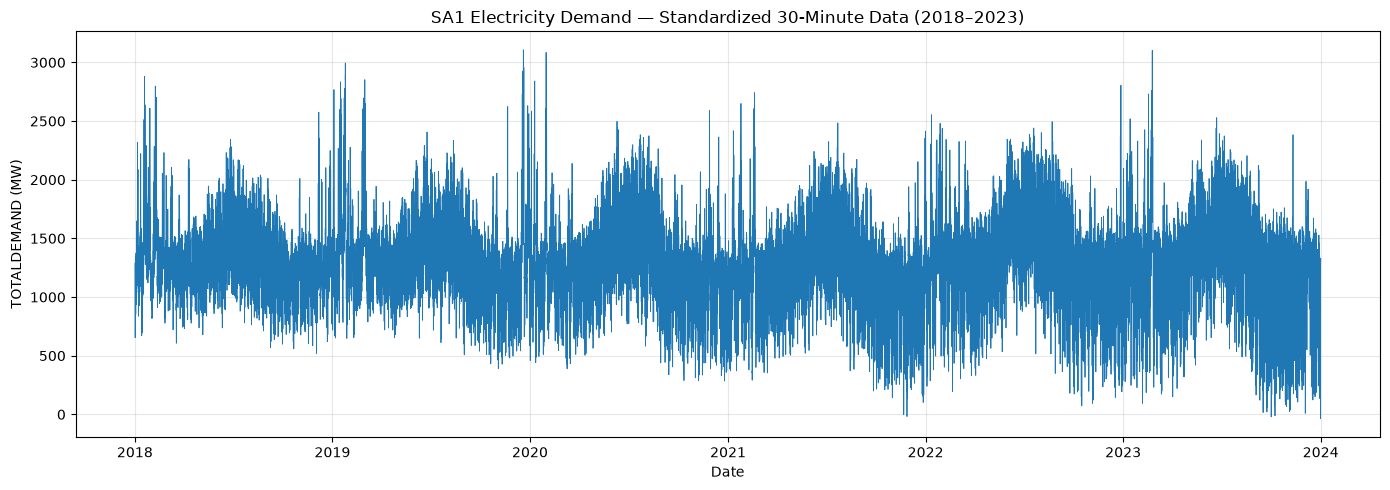

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    sa1_30min["SETTLEMENTDATE"],
    sa1_30min["TOTALDEMAND"],
    linewidth=0.6
)

plt.title("SA1 Electricity Demand — Standardized 30-Minute Data (2018–2023)")
plt.xlabel("Date")
plt.ylabel("TOTALDEMAND (MW)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

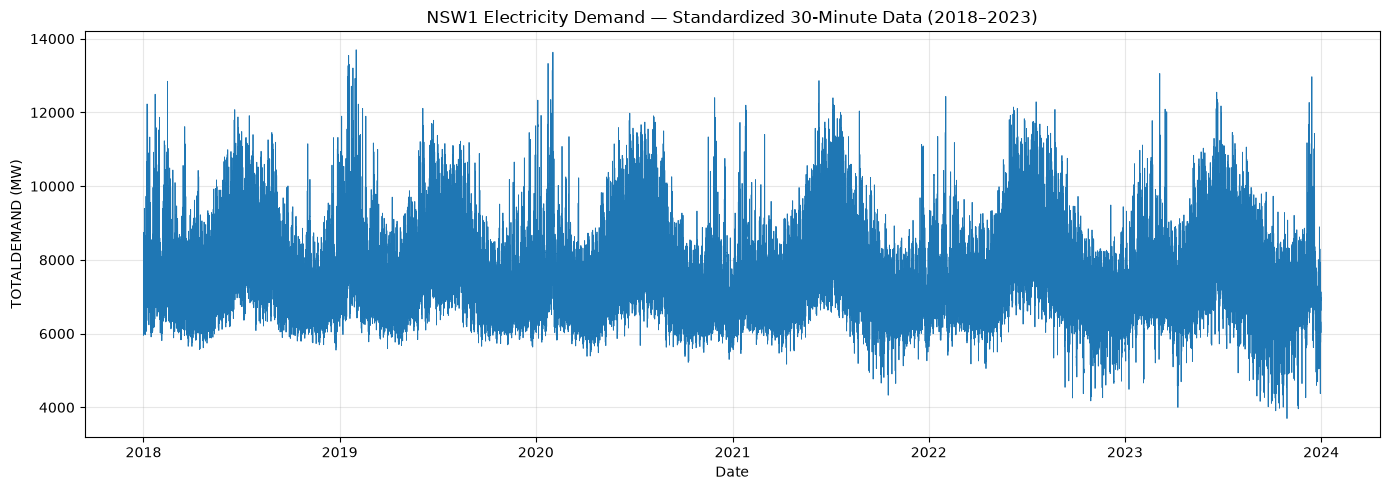

In [21]:
# Plot the full NSW1 electricity demand series (2018–2023)
plt.figure(figsize=(14, 5))

plt.plot(
    nsw1_30min["SETTLEMENTDATE"],
    nsw1_30min["TOTALDEMAND"],
    linewidth=0.6
)

plt.title("NSW1 Electricity Demand — Standardized 30-Minute Data (2018–2023)")
plt.xlabel("Date")
plt.ylabel("TOTALDEMAND (MW)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [22]:
# SA1: Monday-to-Sunday comparison

week_2019_sa1 = sa1_30min[
    (sa1_30min["SETTLEMENTDATE"] >= "2019-03-18 00:00:00")
    &
    (sa1_30min["SETTLEMENTDATE"] < "2019-03-25 00:00:00")
].copy()

week_2021_sa1 = sa1_30min[
    (sa1_30min["SETTLEMENTDATE"] >= "2021-03-15 00:00:00")
    &
    (sa1_30min["SETTLEMENTDATE"] < "2021-03-22 00:00:00")
].copy()

print("2019 observations:", len(week_2019_sa1))
print("2021 observations:", len(week_2021_sa1))

2019 observations: 336
2021 observations: 336


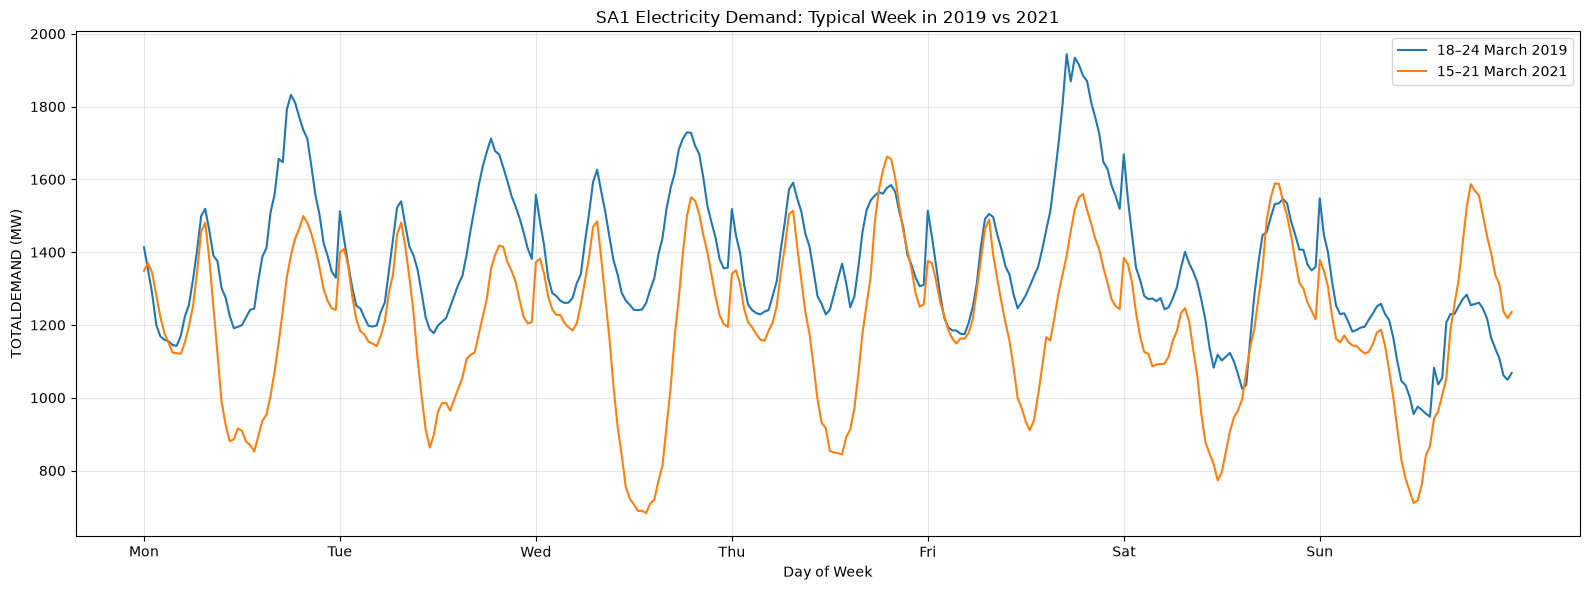

In [23]:
plt.figure(figsize=(16, 6))

x = range(len(week_2019_sa1))

plt.plot(
    x,
    week_2019_sa1["TOTALDEMAND"].values,
    label="18–24 March 2019",
    linewidth=1.5
)

plt.plot(
    x,
    week_2021_sa1["TOTALDEMAND"].values,
    label="15–21 March 2021",
    linewidth=1.5
)

day_positions = [i * 48 for i in range(7)]

day_labels = [
    "Mon", "Tue", "Wed",
    "Thu", "Fri", "Sat", "Sun"
]

plt.xticks(day_positions, day_labels)

plt.title(
    "SA1 Electricity Demand: Typical Week in 2019 vs 2021"
)

plt.xlabel("Day of Week")
plt.ylabel("TOTALDEMAND (MW)")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [24]:
# NSW1: Monday-to-Sunday comparison

week_2019_nsw1 = nsw1_30min[
    (nsw1_30min["SETTLEMENTDATE"] >= "2019-03-18 00:00:00")
    &
    (nsw1_30min["SETTLEMENTDATE"] < "2019-03-25 00:00:00")
].copy()

week_2021_nsw1 = nsw1_30min[
    (nsw1_30min["SETTLEMENTDATE"] >= "2021-03-15 00:00:00")
    &
    (nsw1_30min["SETTLEMENTDATE"] < "2021-03-22 00:00:00")
].copy()

print("2019 observations:", len(week_2019_nsw1))
print("2021 observations:", len(week_2021_nsw1))

2019 observations: 336
2021 observations: 336


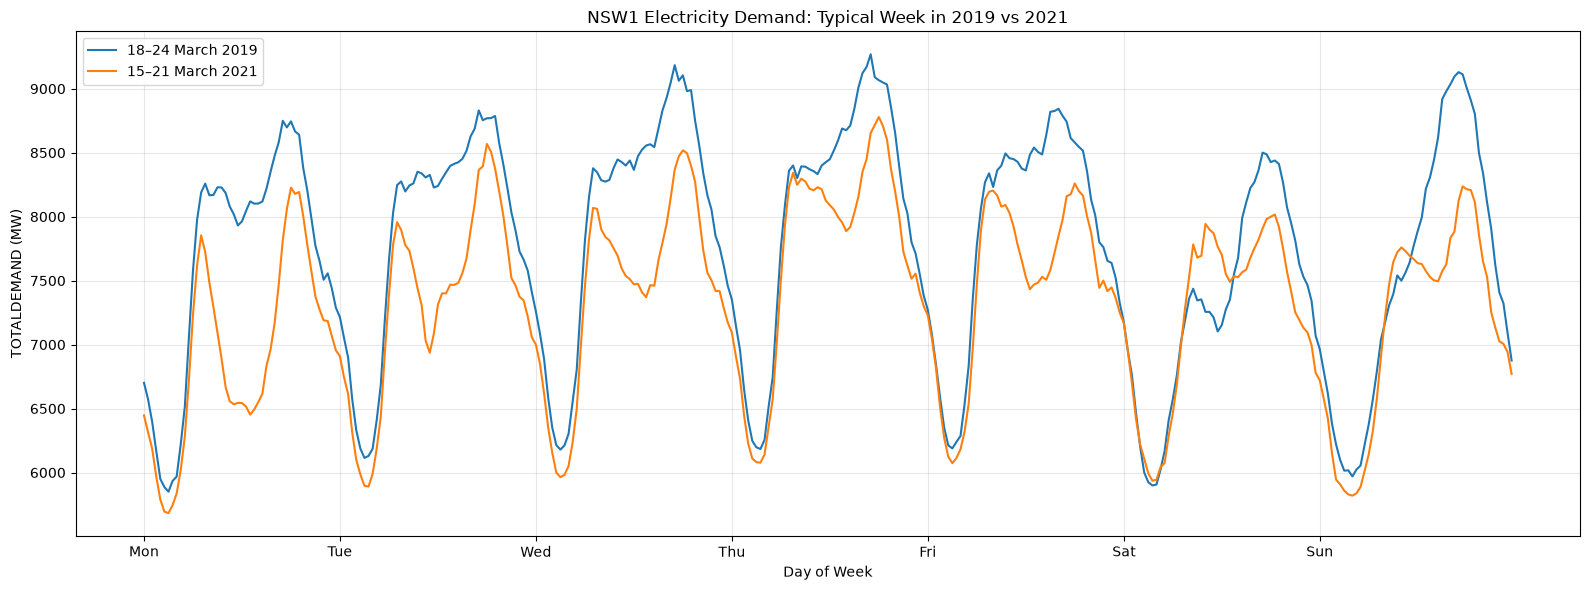

In [25]:
# Compare a typical week in 2019 with the same week in 2021 for NSW1
plt.figure(figsize=(16, 6))

x = range(len(week_2019_nsw1))

plt.plot(
    x,
    week_2019_nsw1["TOTALDEMAND"].values,
    label="18–24 March 2019",
    linewidth=1.5
)

plt.plot(
    x,
    week_2021_nsw1["TOTALDEMAND"].values,
    label="15–21 March 2021",
    linewidth=1.5
)

day_positions = [i * 48 for i in range(7)]

day_labels = [
    "Mon", "Tue", "Wed",
    "Thu", "Fri", "Sat", "Sun"
]

plt.xticks(day_positions, day_labels)

plt.title(
    "NSW1 Electricity Demand: Typical Week in 2019 vs 2021"
)

plt.xlabel("Day of Week")
plt.ylabel("TOTALDEMAND (MW)")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

The selected weeks in 2021 shows a visibly different demand profile compared with the corresponding week in 2019, with generally lower demand levels and deeper troughs on several days. This provides preliminary evidence that electricity-demand behaviour varies over time. However, this visual comparison alone is not sufficient to establish concept drift; further statistical analysis and drift-detection methods are required to determine whether the observed differences represent a persistent change in the underlying data-generating process.